# V3 Dataset — Model Training & Evaluation

This notebook trains and evaluates three models on the V3 student placement dataset,
following the same methodology as `02_model_training.ipynb` (V2) for comparability.

**Models:** Logistic Regression, Random Forest, Gradient Boosting  
**Methodology:** 80/20 stratified split → preprocessing pipeline → train → evaluate → threshold tuning on validation set → final test evaluation

---
## 1. Load the V3 dataset

In [22]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

DATA_PATH = "../data/student_placement_prediction_dataset_v3.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (10000, 15)

Columns:
['age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'communication_skill_score', 'aptitude_score', 'logical_reasoning_score', 'mock_interview_score', 'backlogs', 'placement_status']

First 5 rows:


,age,gender,cgpa,branch,college_tier,internships_count,projects_count,certifications_count,coding_skill_score,communication_skill_score,aptitude_score,logical_reasoning_score,mock_interview_score,backlogs,placement_status
0,23,Male,8.28,ECE,3,1,2,5,78,85,61,68,72,0,Not Placed
1,19,Female,5.35,CSE,2,1,2,3,75,51,59,53,64,0,Not Placed
2,23,Male,7.30,CSE,2,0,2,2,77,82,73,75,74,0,Placed
3,19,Other,8.99,CSE,1,1,2,2,79,57,75,66,63,0,Placed
4,20,Female,5.38,ECE,2,1,1,2,40,43,42,52,51,0,Not Placed


---
## 2. Data Validation

In [23]:
print("=" * 60)
print("DATA VALIDATION")
print("=" * 60)

# Shape
print(f"\n1. Shape: {df.shape[0]} rows x {df.shape[1]} columns")

# Missing values
missing = df.isnull().sum()
print(f"\n2. Missing values:")
if missing.sum() == 0:
    print("   None -- dataset is complete.")
else:
    print(missing[missing > 0])

# Duplicates
dup_count = df.duplicated().sum()
print(f"\n3. Duplicate rows: {dup_count}")

# Target distribution
print(f"\n4. Target distribution (placement_status):")
target_counts = df["placement_status"].value_counts()
target_pcts = df["placement_status"].value_counts(normalize=True) * 100
for label in target_counts.index:
    print(f"   {label}: {target_counts[label]} ({target_pcts[label]:.1f}%)")

# Feature types
print(f"\n5. Feature types:")
print(df.dtypes.to_string())

print(f"\n   Numeric features: {df.select_dtypes(include='number').columns.tolist()}")
print(f"   Categorical features: {df.select_dtypes(include='object').columns.tolist()}")

print("\n" + "=" * 60)
print("VALIDATION COMPLETE")
print("=" * 60)

DATA VALIDATION

1. Shape: 10000 rows x 15 columns

2. Missing values:
   None -- dataset is complete.

3. Duplicate rows: 0

4. Target distribution (placement_status):
   Placed: 5426 (54.3%)
   Not Placed: 4574 (45.7%)

5. Feature types:
age                            int64
gender                           str
cgpa                         float64
branch                           str
college_tier                   int64
internships_count              int64
projects_count                 int64
certifications_count           int64
coding_skill_score             int64
communication_skill_score      int64
aptitude_score                 int64
logical_reasoning_score        int64
mock_interview_score           int64
backlogs                       int64
placement_status                 str

   Numeric features: ['age', 'cgpa', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'communication_skill_score', 'aptitude_score', 'logical_reasoning_

---
## 3. Separate features and target

In [24]:
X = df.drop(columns=["placement_status"])
y = df["placement_status"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print(f"\nInput features ({X.shape[1]}):")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

X shape: (10000, 14)
y shape: (10000,)

Input features (14):
['age', 'gender', 'cgpa', 'branch', 'college_tier', 'internships_count', 'projects_count', 'certifications_count', 'coding_skill_score', 'communication_skill_score', 'aptitude_score', 'logical_reasoning_score', 'mock_interview_score', 'backlogs']

Target distribution:
placement_status
Placed        5426
Not Placed    4574
Name: count, dtype: int64


---
## 4. Train/Test Split (80/20 stratified, random_state=42)

In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (8000, 14)
Test set: (2000, 14)

Training target distribution:
placement_status
Placed        0.542625
Not Placed    0.457375
Name: proportion, dtype: float64

Test target distribution:
placement_status
Placed        0.5425
Not Placed    0.4575
Name: proportion, dtype: float64


---
## 5. Preprocessing Pipeline

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer


numeric_features = [
    "age",
    "cgpa",
    "college_tier",
    "internships_count",
    "projects_count",
    "certifications_count",
    "coding_skill_score",
    "communication_skill_score",
    "aptitude_score",
    "logical_reasoning_score",
    "mock_interview_score",
    "backlogs"
]

categorical_features = [
    "gender",
    "branch"
]


numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])


preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


print("Preprocessor created successfully.")
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Preprocessor created successfully.
Numeric features: 12
Categorical features: 2


---
## 6. Train Models

Same hyperparameters as V2 for comparability.

### 6.1 Logistic Regression

In [27]:
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


### 6.2 Random Forest

In [28]:
from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


### 6.3 Gradient Boosting

In [29]:
from sklearn.ensemble import GradientBoostingClassifier

gradient_boosting_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_pipeline.fit(X_train, y_train)

print("Gradient Boosting trained successfully.")

Gradient Boosting trained successfully.


---
## 7. Evaluate All Three Models

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score
)

models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline,
    "Gradient Boosting": gradient_boosting_pipeline
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    y_true_bin = (y_test == "Placed").astype(int)
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label="Placed"),
        "Recall": recall_score(y_test, y_pred, pos_label="Placed"),
        "F1": f1_score(y_test, y_pred, pos_label="Placed"),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true_bin, (y_pred == "Placed").astype(int)
        ),
        "ROC-AUC": roc_auc_score(y_true_bin, y_prob)
    })

results_df = pd.DataFrame(results)

print("Model Comparison (Test Set @ default threshold 0.50):")
display(results_df.round(4))

Model Comparison (Test Set @ default threshold 0.50):


,Model,Accuracy,Precision,Recall,F1,Macro F1,Balanced Accuracy,ROC-AUC
0,Logistic Regression,0.7485,0.7594,0.7853,0.7721,0.7458,0.7451,0.8214
1,Random Forest,0.7320,0.7444,0.7705,0.7572,0.7291,0.7284,0.8103
2,Gradient Boosting,0.7380,0.7471,0.7816,0.7640,0.7348,0.7340,0.8183


---
## 8. Confusion Matrices


Logistic Regression
[[645 270]
 [233 852]]

Random Forest
[[628 287]
 [249 836]]

Gradient Boosting
[[628 287]
 [237 848]]


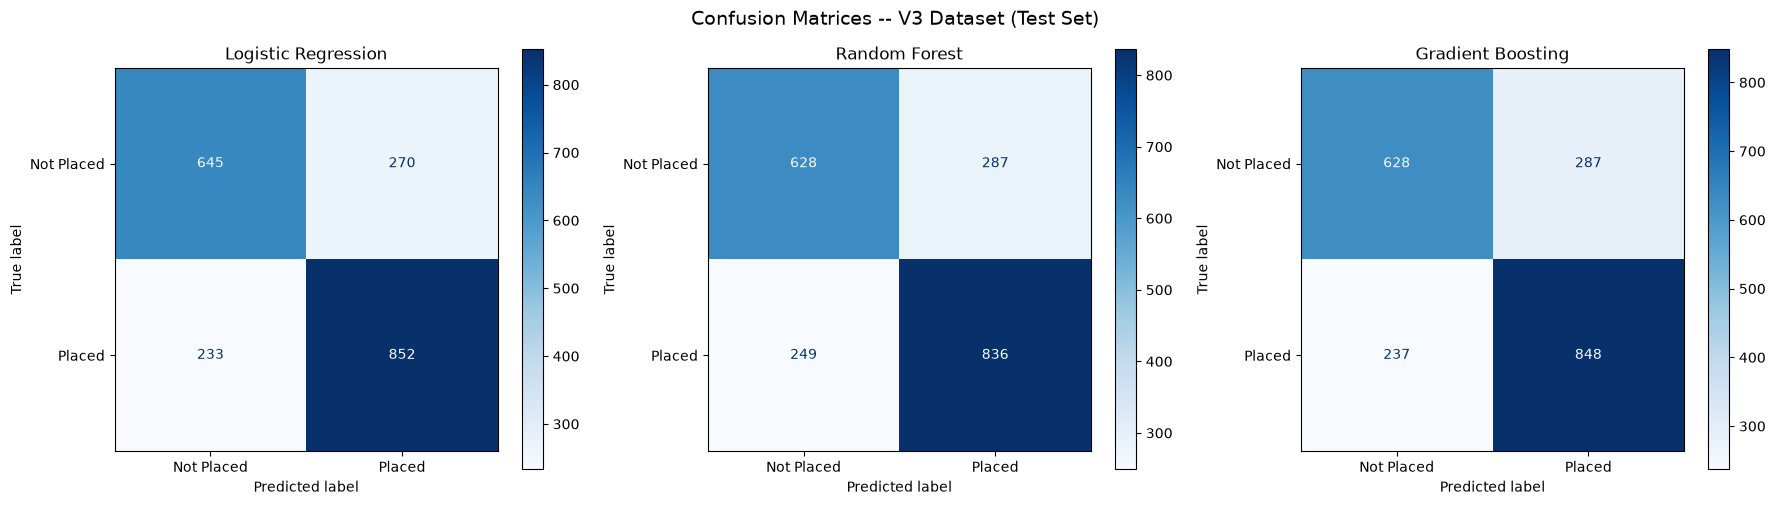

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=["Not Placed", "Placed"])
    
    print(f"\n{name}")
    print(cm)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not Placed", "Placed"]
    )
    disp.plot(ax=axes[idx], cmap="Blues", values_format="d")
    axes[idx].set_title(name)

plt.suptitle("Confusion Matrices -- V3 Dataset (Test Set)", fontsize=14)
plt.tight_layout()
plt.show()

---
## 9. ROC Curves

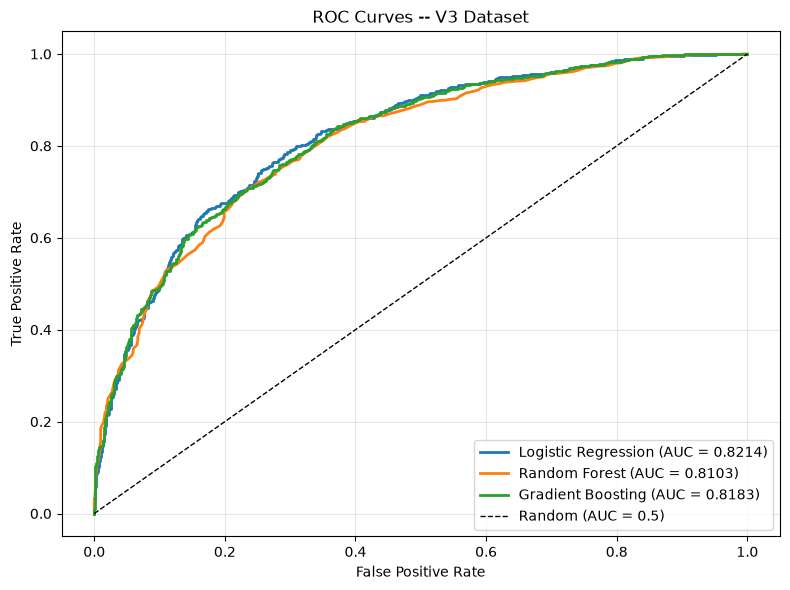

In [11]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8, 6))

y_true_bin = (y_test == "Placed").astype(int)

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_true_bin, y_prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label="Random (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves -- V3 Dataset")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## 10. Overfitting Check -- Train vs Test

In [12]:
overfit_results = []

y_train_bin = (y_train == "Placed").astype(int)
y_test_bin = (y_test == "Placed").astype(int)

for name, model in models.items():
    y_train_pred = model.predict(X_train)
    y_train_prob = model.predict_proba(X_train)[:, 1]
    train_acc = accuracy_score(y_train, y_train_pred)
    train_auc = roc_auc_score(y_train_bin, y_train_prob)
    
    y_test_pred = model.predict(X_test)
    y_test_prob = model.predict_proba(X_test)[:, 1]
    test_acc = accuracy_score(y_test, y_test_pred)
    test_auc = roc_auc_score(y_test_bin, y_test_prob)
    
    overfit_results.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Acc Gap": train_acc - test_acc,
        "Train ROC-AUC": train_auc,
        "Test ROC-AUC": test_auc,
        "AUC Gap": train_auc - test_auc
    })

overfit_df = pd.DataFrame(overfit_results)

print("Overfitting Check -- Train vs Test:")
display(overfit_df.round(4))

print("\nInterpretation:")
for _, row in overfit_df.iterrows():
    name = row["Model"]
    auc_gap = row["AUC Gap"]
    if auc_gap > 0.10:
        print(f"  WARNING  {name}: SIGNIFICANT overfitting (AUC gap = {auc_gap:.4f})")
    elif auc_gap > 0.05:
        print(f"  WARNING  {name}: MODERATE overfitting (AUC gap = {auc_gap:.4f})")
    else:
        print(f"  OK  {name}: Good generalization (AUC gap = {auc_gap:.4f})")

Overfitting Check -- Train vs Test:


,Model,Train Accuracy,Test Accuracy,Acc Gap,Train ROC-AUC,Test ROC-AUC,AUC Gap
0,Logistic Regression,0.7314,0.7485,-0.0171,0.8079,0.8214,-0.0135
1,Random Forest,1.0000,0.7320,0.2680,1.0000,0.8103,0.1897
2,Gradient Boosting,0.7481,0.7380,0.0101,0.8284,0.8183,0.0102



Interpretation:
  OK  Logistic Regression: Good generalization (AUC gap = -0.0135)
  WARNING  Random Forest: SIGNIFICANT overfitting (AUC gap = 0.1897)
  OK  Gradient Boosting: Good generalization (AUC gap = 0.0102)


---
## 11. Threshold Analysis -- All Three Models

Thresholds: 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70  
Metrics: Precision, Recall, F1, Macro F1, Balanced Accuracy

In [13]:
thresholds = [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

y_test_true = (y_test == "Placed").astype(int)

for name, model in models.items():
    print(f"\n{'=' * 60}")
    print(f"Threshold Analysis: {name}")
    print(f"{'=' * 60}")
    
    y_prob = model.predict_proba(X_test)[:, 1]
    
    threshold_results = []
    
    for threshold in thresholds:
        y_pred_t = (y_prob >= threshold).astype(int)
        y_pred_labels = np.where(y_pred_t == 1, "Placed", "Not Placed")
        
        threshold_results.append({
            "Threshold": threshold,
            "Precision": precision_score(y_test_true, y_pred_t),
            "Recall": recall_score(y_test_true, y_pred_t),
            "F1": f1_score(y_test_true, y_pred_t),
            "Macro F1": f1_score(y_test, y_pred_labels, average="macro"),
            "Balanced Accuracy": balanced_accuracy_score(y_test_true, y_pred_t)
        })
    
    threshold_df = pd.DataFrame(threshold_results)
    display(threshold_df.round(4))


Threshold Analysis: Logistic Regression


,Threshold,Precision,Recall,F1,Macro F1,Balanced Accuracy
0,0.40,0.7047,0.8599,0.7746,0.7167,0.7163
1,0.45,0.7315,0.8359,0.7802,0.7376,0.7360
2,0.50,0.7594,0.7853,0.7721,0.7458,0.7451
3,0.55,0.7775,0.7373,0.7569,0.7422,0.7435
4,0.60,0.8020,0.6756,0.7334,0.7335,0.7389
5,0.65,0.8253,0.6138,0.7040,0.7192,0.7299
6,0.70,0.8512,0.5272,0.6511,0.6889,0.7089



Threshold Analysis: Random Forest


,Threshold,Precision,Recall,F1,Macro F1,Balanced Accuracy
0,0.40,0.6923,0.8728,0.7721,0.7054,0.7064
1,0.45,0.7247,0.8323,0.7748,0.7301,0.7287
2,0.50,0.7441,0.7797,0.7615,0.7317,0.7308
3,0.55,0.7753,0.7124,0.7426,0.7315,0.7338
4,0.60,0.7929,0.6350,0.7052,0.7118,0.7192
5,0.65,0.8265,0.5576,0.6659,0.6939,0.7094
6,0.70,0.8618,0.4885,0.6235,0.6726,0.6978



Threshold Analysis: Gradient Boosting


,Threshold,Precision,Recall,F1,Macro F1,Balanced Accuracy
0,0.40,0.7058,0.8645,0.7771,0.7190,0.7186
1,0.45,0.7302,0.8332,0.7783,0.7356,0.7341
2,0.50,0.7471,0.7816,0.7640,0.7348,0.7340
3,0.55,0.7674,0.7207,0.7433,0.7293,0.7309
4,0.60,0.7974,0.6673,0.7265,0.7275,0.7331
5,0.65,0.8308,0.6065,0.7011,0.7184,0.7300
6,0.70,0.8494,0.5198,0.6449,0.6845,0.7053


---
## 12-14. Model Selection

**Decision criteria (in priority order):**
1. Test ROC-AUC (threshold-independent ranking)
2. Macro F1 and Balanced Accuracy
3. Train/test generalization gap (overfitting)
4. Interpretability
5. Model complexity

We do **NOT** choose based on accuracy or F1 alone.

In [14]:
print("=" * 70)
print("MODEL SELECTION ANALYSIS")
print("=" * 70)

selection_data = []

for _, row in results_df.iterrows():
    name = row["Model"]
    overfit_row = overfit_df[overfit_df["Model"] == name].iloc[0]
    
    selection_data.append({
        "Model": name,
        "Test ROC-AUC": row["ROC-AUC"],
        "Test Macro F1": row["Macro F1"],
        "Test Balanced Acc": row["Balanced Accuracy"],
        "Test Accuracy": row["Accuracy"],
        "AUC Gap (overfit)": overfit_row["AUC Gap"],
        "Acc Gap (overfit)": overfit_row["Acc Gap"]
    })

selection_df = pd.DataFrame(selection_data)
display(selection_df.round(4))

# Sort by ROC-AUC descending, then Macro F1, then Balanced Acc
selection_df_sorted = selection_df.sort_values(
    by=["Test ROC-AUC", "Test Macro F1", "Test Balanced Acc"],
    ascending=[False, False, False]
)

best_model_name = selection_df_sorted.iloc[0]["Model"]
best_model_auc = selection_df_sorted.iloc[0]["Test ROC-AUC"]
best_model_auc_gap = selection_df_sorted.iloc[0]["AUC Gap (overfit)"]

print(f"\n{'=' * 70}")
print(f"PRIMARY RANKING BY ROC-AUC: {best_model_name} (AUC = {best_model_auc:.4f})")
print(f"{'=' * 70}")

print(f"\nDetailed reasoning:")

for i, (_, row) in enumerate(selection_df_sorted.iterrows()):
    name = row["Model"]
    print(f"\n  #{i+1} {name}:")
    print(f"      ROC-AUC:          {row['Test ROC-AUC']:.4f}")
    print(f"      Macro F1:         {row['Test Macro F1']:.4f}")
    print(f"      Balanced Acc:     {row['Test Balanced Acc']:.4f}")
    print(f"      AUC overfit gap:  {row['AUC Gap (overfit)']:.4f}")
    if name == "Logistic Regression":
        print(f"      Interpretability: HIGH (linear model, coefficient inspection)")
        print(f"      Complexity:       LOW")
    elif name == "Random Forest":
        print(f"      Interpretability: MEDIUM (feature importances available)")
        print(f"      Complexity:       MEDIUM (200 trees)")
    elif name == "Gradient Boosting":
        print(f"      Interpretability: MEDIUM (feature importances available)")
        print(f"      Complexity:       MEDIUM-HIGH (150 sequential trees)")

print(f"\n{'=' * 70}")

if best_model_auc_gap > 0.10:
    second = selection_df_sorted.iloc[1]
    if second["AUC Gap (overfit)"] < best_model_auc_gap - 0.03:
        best_model_name = second["Model"]
        print(f"OVERRIDE: {best_model_name} selected due to significantly better generalization")
        print(f"despite slightly lower ROC-AUC.")
    else:
        print(f"SELECTED MODEL: {best_model_name}")
        print(f"Note: Model shows overfitting -- consider regularization in future iterations.")
else:
    lr_row = selection_df[selection_df["Model"] == "Logistic Regression"].iloc[0]
    if best_model_name != "Logistic Regression" and abs(best_model_auc - lr_row["Test ROC-AUC"]) < 0.005:
        best_model_name = "Logistic Regression"
        print(f"SELECTED MODEL: {best_model_name}")
        print(f"Reason: Nearly identical ROC-AUC to best, but higher interpretability and lower complexity.")
    else:
        print(f"SELECTED MODEL: {best_model_name}")
        print(f"Reason: Highest ROC-AUC with acceptable generalization.")

print(f"{'=' * 70}")

selected_model = models[best_model_name]

MODEL SELECTION ANALYSIS


,Model,Test ROC-AUC,Test Macro F1,Test Balanced Acc,Test Accuracy,AUC Gap (overfit),Acc Gap (overfit)
0,Logistic Regression,0.8214,0.7458,0.7451,0.7485,-0.0135,-0.0171
1,Random Forest,0.8103,0.7291,0.7284,0.7320,0.1897,0.2680
2,Gradient Boosting,0.8183,0.7348,0.7340,0.7380,0.0102,0.0101



PRIMARY RANKING BY ROC-AUC: Logistic Regression (AUC = 0.8214)

Detailed reasoning:

  #1 Logistic Regression:
      ROC-AUC:          0.8214
      Macro F1:         0.7458
      Balanced Acc:     0.7451
      AUC overfit gap:  -0.0135
      Interpretability: HIGH (linear model, coefficient inspection)
      Complexity:       LOW

  #2 Gradient Boosting:
      ROC-AUC:          0.8183
      Macro F1:         0.7348
      Balanced Acc:     0.7340
      AUC overfit gap:  0.0102
      Interpretability: MEDIUM (feature importances available)
      Complexity:       MEDIUM-HIGH (150 sequential trees)

  #3 Random Forest:
      ROC-AUC:          0.8103
      Macro F1:         0.7291
      Balanced Acc:     0.7284
      AUC overfit gap:  0.1897
      Interpretability: MEDIUM (feature importances available)
      Complexity:       MEDIUM (200 trees)

SELECTED MODEL: Logistic Regression
Reason: Highest ROC-AUC with acceptable generalization.


### Why this model over the other two?

The cell above automatically ranks all three models and prints the reasoning. The decision process:

1. **ROC-AUC is the primary criterion** because it is threshold-independent and measures overall discriminative ability.
2. **Macro F1 and Balanced Accuracy** are secondary tiebreakers -- they account for performance on both classes equally.
3. **Overfitting gap** is a guardrail: if the top model has a huge train-test AUC gap (>0.10), we consider the runner-up.
4. **Interpretability tiebreaker**: If Logistic Regression has nearly the same AUC as the best (within 0.005), we prefer it for its transparency.
5. We deliberately **do not** choose based solely on accuracy or F1, as these can be misleading with imbalanced data.

---
## 15. Threshold Selection on Validation Set (NOT test set)

We split the training data 80/20 into train_final / validation, retrain the selected model, and tune the threshold on the validation set.

In [15]:
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Final training set:", X_train_final.shape)
print("Validation set:", X_val.shape)

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

Final training set: (6400, 14)
Validation set: (1600, 14)

Validation target distribution:
placement_status
Placed        0.5425
Not Placed    0.4575
Name: proportion, dtype: float64


In [16]:
from sklearn.base import clone

selected_model_val = clone(selected_model)
selected_model_val.fit(X_train_final, y_train_final)

print(f"{best_model_name} retrained on {X_train_final.shape[0]} samples for threshold tuning.")

Logistic Regression retrained on 6400 samples for threshold tuning.


In [17]:
y_val_prob = selected_model_val.predict_proba(X_val)[:, 1]
y_val_true = (y_val == "Placed").astype(int)

thresholds = [0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

validation_results = []

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)
    y_val_pred_labels = np.where(y_val_pred == 1, "Placed", "Not Placed")
    
    validation_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_val_true, y_val_pred),
        "Recall": recall_score(y_val_true, y_val_pred),
        "F1": f1_score(y_val_true, y_val_pred),
        "Macro F1": f1_score(y_val, y_val_pred_labels, average="macro"),
        "Balanced Accuracy": balanced_accuracy_score(y_val_true, y_val_pred)
    })

validation_threshold_df = pd.DataFrame(validation_results)

print(f"Threshold Analysis on VALIDATION SET ({best_model_name}):")
display(validation_threshold_df.round(4))

Threshold Analysis on VALIDATION SET (Logistic Regression):


,Threshold,Precision,Recall,F1,Macro F1,Balanced Accuracy
0,0.40,0.6921,0.8779,0.7740,0.7063,0.7074
1,0.45,0.7163,0.8376,0.7722,0.7232,0.7221
2,0.50,0.7418,0.7846,0.7626,0.7314,0.7304
3,0.55,0.7573,0.7442,0.7507,0.7303,0.7307
4,0.60,0.7743,0.6797,0.7239,0.7187,0.7224
5,0.65,0.8083,0.6025,0.6904,0.7060,0.7166
6,0.70,0.8287,0.5184,0.6378,0.6761,0.6957


In [18]:
best_idx = validation_threshold_df["Balanced Accuracy"].idxmax()
BEST_THRESHOLD = validation_threshold_df.loc[best_idx, "Threshold"]
best_val_ba = validation_threshold_df.loc[best_idx, "Balanced Accuracy"]
best_val_macro_f1 = validation_threshold_df.loc[best_idx, "Macro F1"]

print(f"Selected threshold: {BEST_THRESHOLD}")
print(f"Validation Balanced Accuracy: {best_val_ba:.4f}")
print(f"Validation Macro F1: {best_val_macro_f1:.4f}")

Selected threshold: 0.55
Validation Balanced Accuracy: 0.7307
Validation Macro F1: 0.7303


---
## 16. Final Evaluation on Untouched Test Set

Now -- and only now -- we evaluate the selected model + threshold on the test set.

In [19]:
from sklearn.metrics import confusion_matrix, classification_report

final_model = selected_model

y_test_proba = final_model.predict_proba(X_test)[:, 1]

y_test_pred_final = np.where(
    y_test_proba >= BEST_THRESHOLD,
    "Placed",
    "Not Placed"
)

y_test_true_bin = (y_test == "Placed").astype(int)
y_pred_final_bin = (y_test_pred_final == "Placed").astype(int)

final_accuracy = accuracy_score(y_test, y_test_pred_final)
final_precision = precision_score(y_test, y_test_pred_final, pos_label="Placed")
final_recall = recall_score(y_test, y_test_pred_final, pos_label="Placed")
final_f1 = f1_score(y_test, y_test_pred_final, pos_label="Placed")
final_macro_f1 = f1_score(y_test, y_test_pred_final, average="macro")
final_balanced_acc = balanced_accuracy_score(y_test_true_bin, y_pred_final_bin)
final_roc_auc = roc_auc_score(y_test_true_bin, y_test_proba)

final_cm = confusion_matrix(
    y_test,
    y_test_pred_final,
    labels=["Not Placed", "Placed"]
)

print("=" * 60)
print("FINAL TEST RESULTS")
print("=" * 60)
print(f"Selected model:       {best_model_name}")
print(f"Selected threshold:   {BEST_THRESHOLD}")
print(f"")
print(f"Test ROC-AUC:         {final_roc_auc:.4f}")
print(f"Test Macro F1:        {final_macro_f1:.4f}")
print(f"Test Balanced Acc:    {final_balanced_acc:.4f}")
print(f"Test Accuracy:        {final_accuracy:.4f}")
print(f"Test Precision:       {final_precision:.4f}")
print(f"Test Recall:          {final_recall:.4f}")
print(f"Test F1:              {final_f1:.4f}")
print(f"")
print(f"Confusion Matrix:")
print(final_cm)
print(f"")
print(f"Classification Report:")
print(classification_report(
    y_test,
    y_test_pred_final,
    target_names=["Not Placed", "Placed"]
))
print("=" * 60)

FINAL TEST RESULTS
Selected model:       Logistic Regression
Selected threshold:   0.55

Test ROC-AUC:         0.8214
Test Macro F1:        0.7422
Test Balanced Acc:    0.7435
Test Accuracy:        0.7430
Test Precision:       0.7775
Test Recall:          0.7373
Test F1:              0.7569

Confusion Matrix:
[[686 229]
 [285 800]]

Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.71      0.75      0.73       915
      Placed       0.78      0.74      0.76      1085

    accuracy                           0.74      2000
   macro avg       0.74      0.74      0.74      2000
weighted avg       0.74      0.74      0.74      2000



---
## 17. Final Comparison Table & Conclusion

In [20]:
comparison_data = []

for _, row in results_df.iterrows():
    name = row["Model"]
    overfit_row = overfit_df[overfit_df["Model"] == name].iloc[0]
    
    comparison_data.append({
        "Model": name,
        "Test Accuracy": row["Accuracy"],
        "Test Precision": row["Precision"],
        "Test Recall": row["Recall"],
        "Test F1": row["F1"],
        "Test Macro F1": row["Macro F1"],
        "Test Balanced Acc": row["Balanced Accuracy"],
        "Test ROC-AUC": row["ROC-AUC"],
        "Train ROC-AUC": overfit_row["Train ROC-AUC"],
        "AUC Gap": overfit_row["AUC Gap"],
        "Selected": "YES" if name == best_model_name else ""
    })

comparison_df = pd.DataFrame(comparison_data)

print("=" * 80)
print("FULL MODEL COMPARISON TABLE -- V3 Dataset")
print("=" * 80)
display(comparison_df.round(4))

FULL MODEL COMPARISON TABLE -- V3 Dataset


,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Test Macro F1,Test Balanced Acc,Test ROC-AUC,Train ROC-AUC,AUC Gap,Selected
0,Logistic Regression,0.7485,0.7594,0.7853,0.7721,0.7458,0.7451,0.8214,0.8079,-0.0135,YES
1,Random Forest,0.7320,0.7444,0.7705,0.7572,0.7291,0.7284,0.8103,1.0000,0.1897,
2,Gradient Boosting,0.7380,0.7471,0.7816,0.7640,0.7348,0.7340,0.8183,0.8284,0.0102,


In [21]:
print("=" * 70)
print("FINAL CONCLUSION -- V3 Model Training")
print("=" * 70)
print(f"")
print(f"  Selected Model:       {best_model_name}")
print(f"  Selected Threshold:   {BEST_THRESHOLD}")
print(f"")
print(f"  Test ROC-AUC:         {final_roc_auc:.4f}")
print(f"  Test Macro F1:        {final_macro_f1:.4f}")
print(f"  Test Balanced Acc:    {final_balanced_acc:.4f}")
print(f"  Test Accuracy:        {final_accuracy:.4f}")
print(f"")
print(f"  Confusion Matrix:")
print(f"    {final_cm[0]}")
print(f"    {final_cm[1]}")
print(f"")

if final_roc_auc >= 0.85:
    suitability = "YES -- Strong discriminative performance."
elif final_roc_auc >= 0.75:
    suitability = "CONDITIONALLY YES -- Acceptable discrimination, but consider improving features or model tuning."
elif final_roc_auc >= 0.65:
    suitability = "MARGINAL -- Model discriminates better than random but has limited practical utility. Significant improvements needed before production."
else:
    suitability = "NO -- Model discrimination is too weak for reliable predictions. Feature engineering or data improvements required."

print(f"  Suitable for next development stage: {suitability}")
print(f"")
print(f"{'=' * 70}")

print(f"\nModel-Selection Report:")
print(f"-" * 70)
for _, row in comparison_df.iterrows():
    name = row["Model"]
    is_selected = "(SELECTED)" if name == best_model_name else ""
    print(f"\n  {name} {is_selected}")
    print(f"    ROC-AUC: {row['Test ROC-AUC']:.4f}  |  Macro F1: {row['Test Macro F1']:.4f}  |  Balanced Acc: {row['Test Balanced Acc']:.4f}")
    print(f"    AUC Gap (overfit): {row['AUC Gap']:.4f}")
    if name == "Logistic Regression":
        print(f"    Pros: Highly interpretable, low complexity, fast training, minimal overfitting risk.")
        print(f"    Cons: Cannot capture nonlinear feature interactions.")
    elif name == "Random Forest":
        print(f"    Pros: Handles nonlinearity, robust to outliers, parallelizable.")
        print(f"    Cons: Can overfit on noisy features, higher memory usage, less interpretable than LR.")
    elif name == "Gradient Boosting":
        print(f"    Pros: Often achieves best discrimination, handles feature interactions well.")
        print(f"    Cons: Sequential training (slower), higher complexity, more prone to overfitting.")

print(f"\n{'=' * 70}")
print("NOTEBOOK COMPLETE")
print(f"{'=' * 70}")

FINAL CONCLUSION -- V3 Model Training

  Selected Model:       Logistic Regression
  Selected Threshold:   0.55

  Test ROC-AUC:         0.8214
  Test Macro F1:        0.7422
  Test Balanced Acc:    0.7435
  Test Accuracy:        0.7430

  Confusion Matrix:
    [686 229]
    [285 800]

  Suitable for next development stage: CONDITIONALLY YES -- Acceptable discrimination, but consider improving features or model tuning.


Model-Selection Report:
----------------------------------------------------------------------

  Logistic Regression (SELECTED)
    ROC-AUC: 0.8214  |  Macro F1: 0.7458  |  Balanced Acc: 0.7451
    AUC Gap (overfit): -0.0135
    Pros: Highly interpretable, low complexity, fast training, minimal overfitting risk.
    Cons: Cannot capture nonlinear feature interactions.

  Random Forest 
    ROC-AUC: 0.8103  |  Macro F1: 0.7291  |  Balanced Acc: 0.7284
    AUC Gap (overfit): 0.1897
    Pros: Handles nonlinearity, robust to outliers, parallelizable.
    Cons: Can overfit